In [1]:
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt

# **Step 1: Load the Data**

In [2]:
# Assuming your data is loaded into a DataFrame named 'df'
# You might need to adjust this based on how your actual data is loaded
# df = pd.read_csv("/kaggle/input/bangladesh-historical-weather-dataset-2008-2023/Bangladesh Historical Weather Dataset 2008-2023.csv")

data_01 = pd.read_csv('data-01.csv')
data_02 = pd.read_csv('data-02.csv')
data_03 = pd.read_csv('data-03.csv')
data_04 = pd.read_csv('data-04.csv')
data_05 = pd.read_csv('data-05.csv')

# Concaténation en un seul DataFrame
df = pd.concat([data_01, data_02, data_03, data_04, data_05], ignore_index=True)
print('Shape du DataFrame concaténé:', df.shape)
print('Colonnes disponibles:', df.columns.tolist())
df.head()

Shape du DataFrame concaténé: (3658, 33)
Colonnes disponibles: ['name', 'datetime', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob', 'precipcover', 'preciptype', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise', 'sunset', 'moonphase', 'conditions', 'description', 'icon', 'stations']


,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Ouagadougou,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,...,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,0.37,Partially cloudy,Clearing in the afternoon.,partly-cloudy-day,"65503099999,DFFD"
1,Ouagadougou,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,...,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,0.40,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
2,Ouagadougou,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,...,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,0.44,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
3,Ouagadougou,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,...,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"
4,Ouagadougou,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,...,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,0.50,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"


# **Step 2: Preprocessing the Data**

In [3]:
# Conversion de la colonne datetime
df['datetime'] = pd.to_datetime(df['datetime'])

# Suppression des lignes avec datetime, temp ou precip manquants
df = df.dropna(subset=['datetime', 'temp', 'precip'])

# Tri chronologique et réinitialisation de l'index
df = df.sort_values('datetime').reset_index(drop=True)

print(f'Shape après nettoyage : {df.shape}')
print(f'Période : {df["datetime"].min().date()} → {df["datetime"].max().date()}')
df.head()

Shape après nettoyage : (3658, 33)
Période : 2015-01-01 → 2025-01-01


,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Ouagadougou,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,...,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,0.37,Partially cloudy,Clearing in the afternoon.,partly-cloudy-day,"65503099999,DFFD"
1,Ouagadougou,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,...,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,0.40,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
2,Ouagadougou,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,...,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,0.44,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
3,Ouagadougou,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,...,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"
4,Ouagadougou,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,...,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,0.50,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"


# **Step 3: Scaling Data (Not needed for Prophet)**

# **Step 4: Split the dataset into training and testing sets**

In [4]:
# Split chronologique 80/20 (pas de shuffle pour une série temporelle)
train_size = int(len(df) * 0.8)
train = df.iloc[:train_size].reset_index(drop=True)
test  = df.iloc[train_size:].reset_index(drop=True)

print(f'Train : {len(train)} lignes  ({train["datetime"].min().date()} → {train["datetime"].max().date()})')
print(f'Test  : {len(test)}  lignes  ({test["datetime"].min().date()} → {test["datetime"].max().date()})')

Train : 2926 lignes  (2015-01-01 → 2023-01-01)
Test  : 732  lignes  (2023-01-01 → 2025-01-01)


# **Step 5: Model Building**

In [5]:
model = Prophet()

# **Step 6: Training**

In [6]:
# Prophet attend les colonnes 'ds' (date) et 'y' (valeur)
train_prophet = train[['datetime', 'temp']].rename(columns={'datetime': 'ds', 'temp': 'y'})
model.fit(train_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


# **Step 7: Predictions and Model evaluation**

In [7]:
future = model.make_future_dataframe(periods=len(test), freq='D')
forecast = model.predict(future)

# **Step 8: Calculate the evaluation metrics**

In [8]:
mse = mean_squared_error(test['temp'], forecast.iloc[-len(test):]['yhat'])
rmse = np.sqrt(mse)
mae = mean_absolute_error(test['temp'], forecast.iloc[-len(test):]['yhat'])
def mean_absolute_percentage_error(y_true, y_pred):
    """MAPE robuste : ignore les valeurs réelles nulles (division par zéro)."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
mape = mean_absolute_percentage_error(test['temp'], forecast.iloc[-len(test):]['yhat'])

In [9]:
# Display the metrics
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Absolute Percentage Error (MAPE): {mape}')

Mean Squared Error (MSE): 16.627609194561604
Root Mean Squared Error (RMSE): 4.077696554988074
Mean Absolute Error (MAE): 3.437264440475874
Mean Absolute Percentage Error (MAPE): 3.9805528997277544


# **Step 9: Actual vs Predicted**

In [10]:
future_30_days = model.make_future_dataframe(periods=1578, freq='D')
forecast_30_days = model.predict(future_30_days)
forecast_30_days

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2015-01-01,83.969007,72.355323,79.443225,83.969007,83.969007,-7.829355,-7.829355,-7.829355,0.078524,0.078524,0.078524,-7.907879,-7.907879,-7.907879,0.0,0.0,0.0,76.139652
1,2015-01-02,83.968457,72.508847,79.343473,83.968457,83.968457,-7.940338,-7.940338,-7.940338,-0.022099,-0.022099,-0.022099,-7.918239,-7.918239,-7.918239,0.0,0.0,0.0,76.028119
2,2015-01-03,83.967907,72.326666,79.566763,83.967907,83.967907,-8.139012,-8.139012,-8.139012,-0.224789,-0.224789,-0.224789,-7.914223,-7.914223,-7.914223,0.0,0.0,0.0,75.828895
3,2015-01-04,83.967357,72.607360,79.514602,83.967357,83.967357,-7.866556,-7.866556,-7.866556,0.030255,0.030255,0.030255,-7.896811,-7.896811,-7.896811,0.0,0.0,0.0,76.100801
4,2015-01-05,83.966807,72.773346,79.879555,83.966807,83.966807,-7.788662,-7.788662,-7.788662,0.078340,0.078340,0.078340,-7.867001,-7.867001,-7.867001,0.0,0.0,0.0,76.178145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4496,2027-04-24,78.523150,83.523542,91.323568,76.870922,80.345360,8.898507,8.898507,8.898507,-0.224789,-0.224789,-0.224789,9.123296,9.123296,9.123296,0.0,0.0,0.0,87.421657
4497,2027-04-25,78.520325,83.894874,91.645479,76.868359,80.345035,9.173017,9.173017,9.173017,0.030255,0.030255,0.030255,9.142761,9.142761,9.142761,0.0,0.0,0.0,87.693341
4498,2027-04-26,78.517500,83.790721,91.722622,76.864260,80.344710,9.225885,9.225885,9.225885,0.078340,0.078340,0.078340,9.147546,9.147546,9.147546,0.0,0.0,0.0,87.743385
4499,2027-04-27,78.514675,83.921980,91.791149,76.859099,80.344384,9.182743,9.182743,9.182743,0.045531,0.045531,0.045531,9.137212,9.137212,9.137212,0.0,0.0,0.0,87.697418


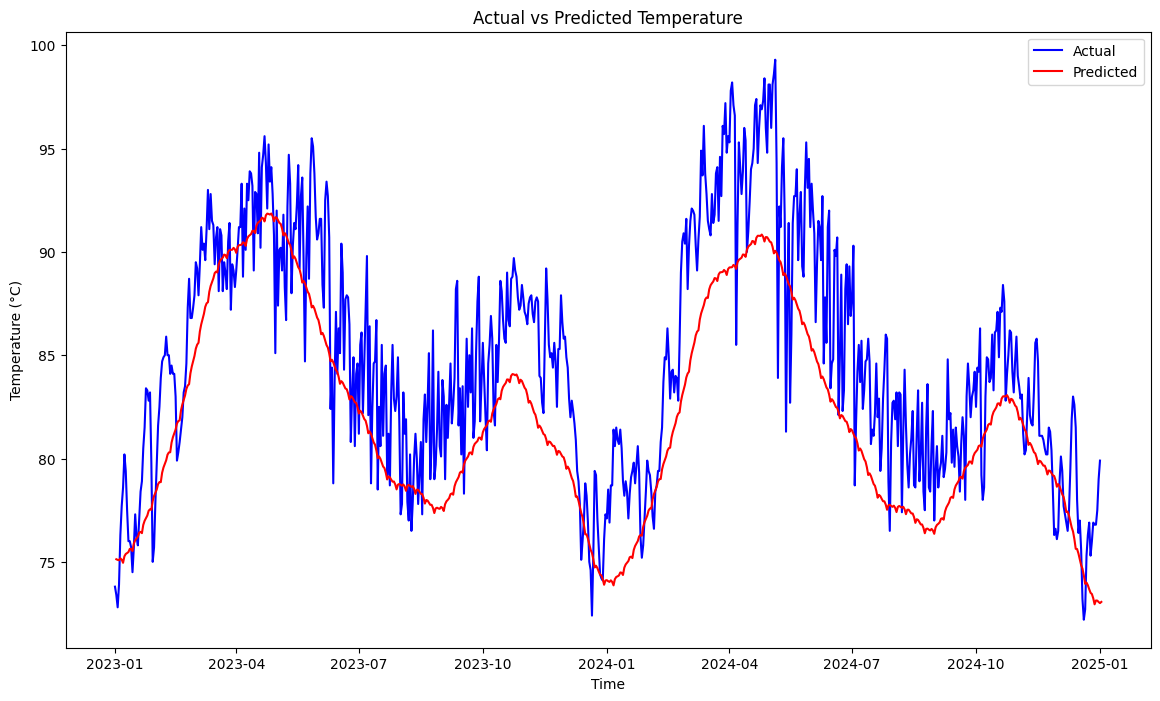

In [11]:
# Plot actual vs predicted
plt.figure(figsize=(14, 8))
plt.plot(test['datetime'], test['temp'], label='Actual', color='blue')
plt.plot(forecast.iloc[-len(test):]['ds'], forecast.iloc[-len(test):]['yhat'], label='Predicted', color='red')
plt.title('Actual vs Predicted Temperature')
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

In [12]:
import pandas as pd
# Create a DataFrame with actual and predicted values
result_df = pd.DataFrame({
    'Time': test['datetime'],
    'Actual': test['temp'],
    'Predicted': forecast.iloc[-len(test):]['yhat'],
})

# Display the DataFrame
print(result_df)

           Time  Actual  Predicted
0    2023-01-01    73.8        NaN
1    2023-01-02    73.4        NaN
2    2023-01-03    72.8        NaN
3    2023-01-04    73.9        NaN
4    2023-01-05    76.3        NaN
...         ...     ...        ...
3650        NaT     NaN  73.130300
3651        NaT     NaN  73.125368
3652        NaT     NaN  73.056088
3653        NaT     NaN  73.004070
3654        NaT     NaN  73.062478

[1464 rows x 3 columns]


# **Step 10: Future Weather Prediction**

In [13]:
from prophet import Prophet
from prophet.plot import plot_plotly, plot_components_plotly

forecasts = model.make_future_dataframe(periods=1578)
predictions = model.predict(forecasts)
plot_plotly(model, predictions)

# **Rainfall**

In [14]:
df.head()

,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Ouagadougou,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,...,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,0.37,Partially cloudy,Clearing in the afternoon.,partly-cloudy-day,"65503099999,DFFD"
1,Ouagadougou,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,...,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,0.40,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
2,Ouagadougou,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,...,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,0.44,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
3,Ouagadougou,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,...,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"
4,Ouagadougou,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,...,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,0.50,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"


In [15]:
model_rainfall = Prophet()

In [16]:
# 'precip' est la colonne précipitations dans le dataset Visual Crossing (mm/jour)
train_rainfall = train[['datetime', 'precip']].rename(columns={'datetime': 'ds', 'precip': 'y'})
model_rainfall.fit(train_rainfall)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [17]:
future = model_rainfall.make_future_dataframe(periods=len(test), freq='D')
forecast = model_rainfall.predict(future)

In [18]:
mse  = mean_squared_error(test['precip'], forecast.iloc[-len(test):]['yhat'].values)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(test['precip'], forecast.iloc[-len(test):]['yhat'].values)
def mean_absolute_percentage_error(y_true, y_pred):
    """MAPE robuste : ignore les valeurs réelles nulles (division par zéro)."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
mape = mean_absolute_percentage_error(test['precip'], forecast.iloc[-len(test):]['yhat'].values)

/tmp/ipykernel_27942/3919630835.py:6: RuntimeWarning:

divide by zero encountered in divide



In [19]:
# Display the metrics
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Absolute Percentage Error (MAPE): {mape}')

Mean Squared Error (MSE): 0.10942286779173234
Root Mean Squared Error (RMSE): 0.33079127526543434
Mean Absolute Error (MAE): 0.14798877447342546
Mean Absolute Percentage Error (MAPE): inf


In [20]:
future_30_days = model_rainfall.make_future_dataframe(periods=1578, freq='D')
forecast_30_days = model_rainfall.predict(future_30_days)
forecast_30_days.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
4496,2027-04-24,0.127520,-0.393896,0.443849,0.117337,0.137303,-0.112717,-0.112717,-0.112717,-0.012957,-0.012957,-0.012957,-0.099760,-0.099760,-0.099760,0.0,0.0,0.0,0.014803
4497,2027-04-25,0.127533,-0.426014,0.494573,0.117334,0.137322,-0.105164,-0.105164,-0.105164,-0.008929,-0.008929,-0.008929,-0.096235,-0.096235,-0.096235,0.0,0.0,0.0,0.022369
4498,2027-04-26,0.127546,-0.402893,0.502938,0.117332,0.137340,-0.089024,-0.089024,-0.089024,0.002923,0.002923,0.002923,-0.091947,-0.091947,-0.091947,0.0,0.0,0.0,0.038522
4499,2027-04-27,0.127560,-0.358086,0.536495,0.117330,0.137358,-0.071489,-0.071489,-0.071489,0.015460,0.015460,0.015460,-0.086949,-0.086949,-0.086949,0.0,0.0,0.0,0.056071
4500,2027-04-28,0.127573,-0.358259,0.510386,0.117329,0.137377,-0.067283,-0.067283,-0.067283,0.014028,0.014028,0.014028,-0.081310,-0.081310,-0.081310,0.0,0.0,0.0,0.060291


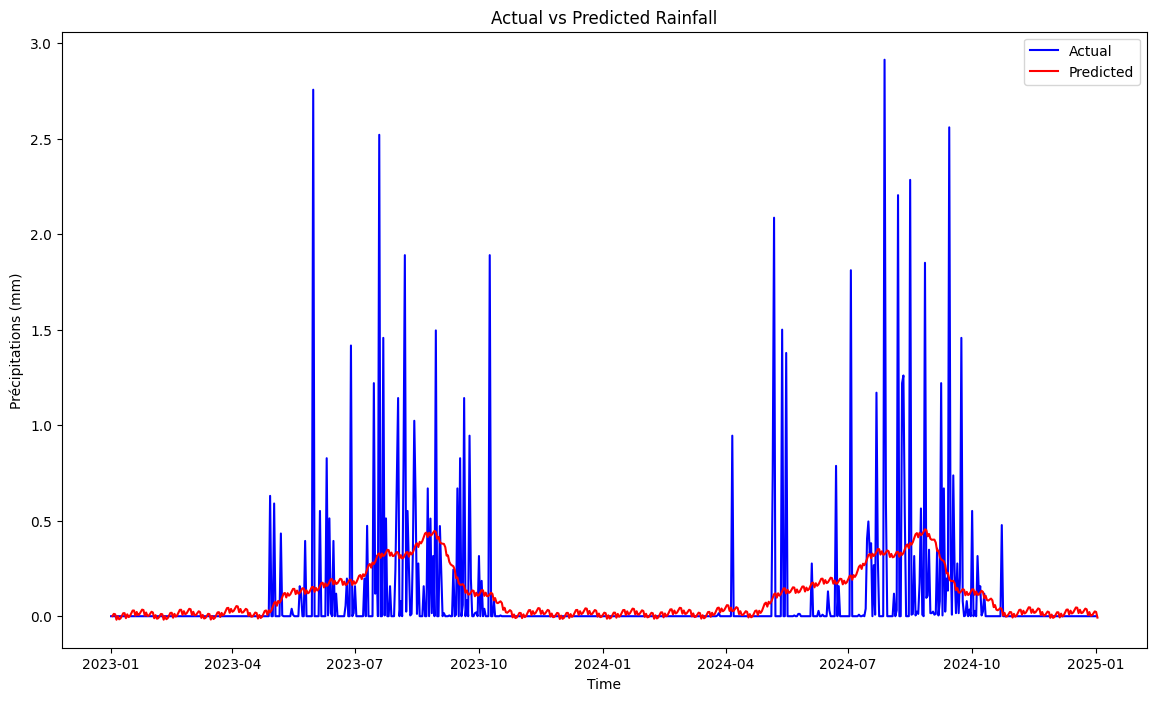

In [21]:
# Plot actual vs predicted
plt.figure(figsize=(14, 8))
plt.plot(test['datetime'], test['precip'], label='Actual', color='blue')
plt.plot(forecast.iloc[-len(test):]['ds'], forecast.iloc[-len(test):]['yhat'], label='Predicted', color='red')
plt.title('Actual vs Predicted Rainfall')
plt.xlabel('Time')
plt.ylabel('Précipitations (mm)')
plt.legend()
plt.show()

In [22]:
import pandas as pd
# Create a DataFrame with actual and predicted values
result_df = pd.DataFrame({
    'Time': test['datetime'],
    'Actual': test['precip'],
    'Predicted': forecast.iloc[-len(test):]['yhat'],
})

# Display the DataFrame
print(result_df)

           Time  Actual  Predicted
0    2023-01-01     0.0        NaN
1    2023-01-02     0.0        NaN
2    2023-01-03     0.0        NaN
3    2023-01-04     0.0        NaN
4    2023-01-05     0.0        NaN
...         ...     ...        ...
3650        NaT     NaN   0.004553
3651        NaT     NaN   0.014410
3652        NaT     NaN   0.025166
3653        NaT     NaN   0.022223
3654        NaT     NaN  -0.007287

[1464 rows x 3 columns]


In [23]:
forecasts = model_rainfall.make_future_dataframe(periods=1578)
predictions = model_rainfall.predict(forecasts)
plot_plotly(model_rainfall, predictions)